# Housing Index Mexico

Notebook to create the New Housing Price Index for Mexico as a whole and for its main metropolitan areas

@roman

8/10/2025

In [35]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker
import matplotlib.colors as mcolors
import seaborn as sns
import yaml
import warnings
from shapely.geometry import Polygon
from tqdm import tqdm

import statsmodels.formula.api as smf
import statsmodels.api as sm
import h3
from dotenv import load_dotenv

import mlflow
import joblib
import xgboost as xgb
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split
from scipy.stats import bootstrap

from INEGIpy import MarcoGeoestadistico
from s3_xgboost_training import FeatureTransformer, get_configs, get_target_value, get_predictions

In [2]:
# Settings
pd.set_option('display.max_columns', 500)

# Load environment variables
load_dotenv()

# inegi class
inegi_api = MarcoGeoestadistico()

# suppress seaborn warnings
warnings.filterwarnings("ignore", module="seaborn")
warnings.filterwarnings("ignore", module="pandas")

---
# Settings

In [3]:
# Settings
# dir
DIR_DATA = '../../data'
DIR_RESULTS = '../../results'
DIR_MODELS = '../../models'
FILE_PROPERTIES = f"{DIR_DATA}/processed/properties_predicted_1ec464a33bdc436295dbb3c05e3c6ecb.parquet"

# config
CONFIG_PATH = 'config_xgb.yaml'
MODEL_ID = '6c4b07101200430da8a657815014af7f'

---
# Data & Model

## Data

In [5]:
# read parquet, index is observation_id
df_properties = pd.read_parquet(FILE_PROPERTIES)

# set index
df_properties = df_properties.set_index('observation_id')

# new features
first_date_obs = df_properties['valuation_date'].min()
df_properties = (
    df_properties
    .assign(
        # quarters since appraisal
        quarters_since_first_appraisal=lambda x: (
            x['valuation_date'] - first_date_obs
            ).dt.days / (30.4 * 3),
        # recategorizations
        is_new=lambda x:
            np.where(x['age_in_months'].le(1), 'new', 'used'),
        conservacion_recat=lambda x:
            x['conservation_status_id'].replace({7: 3.5}).astype(int),
        is_renovated=lambda x:
            np.where(x['conservation_status_id'].ge(7), 'renovated', 'not_renovated'),
        is_apartment=lambda x:
            np.where(x['property_type_id'].ge(4), 1, 0),
        has_elevator=lambda x:
            np.where(x['elevator_service_id'].eq(1), 1, 0),
    )
    .assign(
        is_new=lambda x: x['is_new'].astype('category'),
    )
)

# look
print(df_properties.shape)
df_properties.head()

(1908483, 138)


,y,y_pred,y_fitted,y_pred_fitted,set,half_bathrooms,full_bathrooms,property_class_more_common_in_area,neighborhood,constructor,zip_code,age_in_months,parking_lots,valuation_date,potable_water_service_id,lighting_service_id,sidewalk_id,project_quality_id,property_class_id,conservation_status_id,controller_id,elevator_service_id,state_id,equipment_id,curb_id,infrastructure_service_id,road_materials_id,municipality_id,grantor_id,urban_proximity_id,water_collection_service_id,electrical_supply_service_id,telephone_service_supply_id,property_type_id,public_transportation_service_id,valuation_unit_id,valuation_professional_id,level,total_levels,purpose_of_appraisal,bedrooms,built_area,saleable_area,land_area,rentable_units,rentable_units_subject_property,current_use,market_price,price,built_price,land_price,access_routes,remaining_useful_life,property_id,city_cluster,ppsm_comps,ppsm_lower_comps,ppsm_upper_comps,num_neighbors,distance_to_ocean,ocean_label,accessory_area,hex_id,count_supermarkets_at_1km,count_hospitals_at_5km,count_metro_at_1km,count_schools_at_1km,count_restaurants_at_1km,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,mayores,menores,p12_64,p65mas,percep_ing,ing_cor,estim_alqu,otros_ing,gasto_mon,vivienda,alquiler,pred_cons,cuidados,tipo_viv,antiguedad,cuart_dorm,tenencia,renta,estim_pago,pago_viv,pago_mesp,tipo_adqui,viv_usada,tipo_finan,escrituras,tot_resid,tot_hom,tot_muj,tot_hog,total_viviendas,lag_year_inpc,lag_3months_em_avg_pct_change_inpc,lag_year_general_minimum_wage,lag_3months_em_avg_general_wage,ppsm_terrain,ppsm_terrain_lower,ppsm_terrain_upper,hex_longitude,hex_latitude,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,longitude,latitude,quarters_since_first_appraisal,is_new,conservacion_recat,is_renovated,is_apartment,has_elevator
observation_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
148dd882-8cec-434d-ab33-a762faa426c2,10525.000000,10582.937500,-0.502343,-0.489939,train,0,1,3,REGION 065,NO APLICA,77723,0,0,2019-04-12,1,3,1,1,3,6,34e46c5f-11c3-4c22-afc4-ead80d8e108b,2,23,3,1,3,2,008,98013144-6a9f-4e08-9255-cb54568d2f5a,3,1,2,2,4,1,bfe2dd96-5fa8-43e8-b679-533e42090d64,6a9c3931-ae31-4d41-8403-a0098c9e9d38,4,2,S/D,2,40,40,50,4,1,TERRENO DONDE SE DESPLANTA EL CONJUNTO HABITAC...,421072,421000,242460,95950,EL ACCESO AL DESARROLLO ES POR LA CARRETERA CA...,60,24128a64-abb5-5265-8f52-778f41b603f8,8,10457,10308,10609,60,10000,mar_caribe,0.000000,89450a1808bffff,0,0,0,0,0,1.000000,2.125000,2,1,38.12500,6.585938,3.261719,2.603516,0.659180,2.560547,0.042419,2.132812,56480.390625,4058.396729,65.036064,41352.601562,7123.578613,5199.178711,75.620903,1589.596558,1.0,6.351562,1.490234,1,1766.300659,1384.307861,337.991119,0.716116,1.0,0.049561,1,1,3.265625,1.757812,1.508789,1.004883,72896,99.1250,0.004471,103.8750,0.049988,2546,1038,4975,20.678519,-87.132648,-0.200028,-1.361624,-1.072907,0.740351,1.365730,-2.597566,-0.017984,-0.959619,-2.840051,-1.403227,1.158682,0.741836,-3.145484,0.717600,-2.009741,0.159004,-87.131744,20.679223,1.107456,new,6,not_renovated,1,0
5bd351c1-1438-47f2-bbb1-659cb11a34bf,58698.795181,55339.792969,3.380725,3.247587,train,0,2,4,ZONA CENTRO,<NA>,64000,0,2,2022-09-06,1,3,1,1,4,6,72a0ca56-6a9f-4563-a1c1-d44940471b06,2,19,4,1,4,2,039,b6ec5872-8e1c-4a3e-908f-5dc1ab822e5b,1,1,1,1,4,1,75fe9a3c-92a0-4623-925b-955a08effd0c,9405d735-b727-408c-99d7-3386780ba26b,23,1,S/D,2,77,83,12,871,1,LOTE DE TERRENO URBANO EN EL CUAL SE DESARROLL...,4872472,4872000,1580038,289239,Por Ave. Constitución de Primer orden y de Alt...,70,8492b9ed-8046-5960-bea3-8d868993e7be,4,51787,4313

## Cities

In [6]:
# read cities shapes in parquet
gdf_cities = gpd.read_parquet(f"{DIR_DATA}/misc/cities.parquet")

# look
print(gdf_cities.shape)
gdf_cities.head()


(114, 3)


,geometry,cluster,total_properties
0,"POLYGON ((3766192.137 1038920.719, 3766072.241...",0,49294
1,"POLYGON ((2106201.674 1838908.292, 2106105.496...",1,41078
2,"POLYGON ((2083964.935 2167068.796, 2083854.591...",2,49914
3,"POLYGON ((3695976.760 913468.113, 3695883.500 ...",3,4945
4,"POLYGON ((2691489.214 1478562.321, 2691414.834...",4,224732


## Embeddings

In [7]:
# read parquet
gdf_hex_embeddings = pd.read_parquet("../../data/misc/hex_embeddings_d16_v2.parquet")

# columns with hex_embeddings add sufix d16
gdf_hex_embeddings = gdf_hex_embeddings.rename(
    columns=lambda x: x + "_d16_v2" if x not in ["hex_id"] else x
)

# look
print(gdf_hex_embeddings.shape)
gdf_hex_embeddings.head()

(261712, 17)


,hex_id,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2
0,89450984803ffff,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302
1,89450984807ffff,1.244653,-2.061231,0.867655,-0.035147,1.327668,-3.105197,0.259648,-0.149245,-1.162221,-1.612379,0.207615,0.977444,-3.007813,-0.191676,-2.067218,-1.100550
2,8945098480bffff,1.298778,-2.005947,1.099923,-0.111693,1.201540,-3.093980,0.316485,-0.050870,-1.329637,-1.730504,0.155120,1.143537,-3.026915,-0.121923,-2.051444,-1.063948
3,8945098480fffff,1.197906,-1.991767,0.976100,-0.100657,1.437752,-3.219944,0.211685,-0.054004,-1.168892,-1.820608,0.153301,0.834648,-2.919081,-0.141560,-1.947374,-1.189573
4,89450984813ffff,1.243597,-1.919230,1.025213,0.056413,1.146621,-3.069181,0.277293,-0.204666,-1.146666,-1.496874,0.192501,1.269446,-3.082055,-0.237326,-2.271990,-0.919029


## Mexico states shapes

<Axes: >

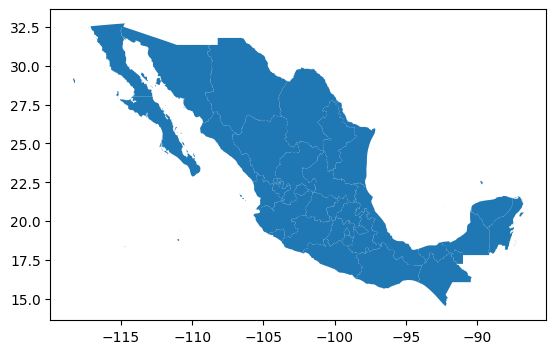

In [8]:
# get mexico shapes
gdf_mexico_states = inegi_api.Entidades()
gdf_mexico_states.shape
gdf_mexico_states.plot()

In [9]:
# look states
gdf_mexico_states.head()

,geometry,cvegeo,cve_agee,nom_agee,nom_abrev,pob,pob_fem,pob_mas,viv
0,"MULTIPOLYGON (((-102.29739 22.45527, -102.2955...",01,01,Aguascalientes,Ags.,1425607,728924,696683,386671
1,"MULTIPOLYGON (((-114.11561 28.09639, -114.1152...",02,02,Baja California,BC,3769020,1868431,1900589,1149563
2,"MULTIPOLYGON (((-109.89451 22.87476, -109.8946...",03,03,Baja California Sur,BCS,798447,392568,405879,240660
3,"MULTIPOLYGON (((-91.95650 20.19700, -91.95636 ...",04,04,Campeche,Camp.,928363,471424,456939,260824
4,"MULTIPOLYGON (((-102.31549 29.88000, -102.3150...",05,05,Coahuila de Zaragoza,Coah.,3146771,1583102,1563669,901249


## Mexico Municipalities shapes

<Axes: >

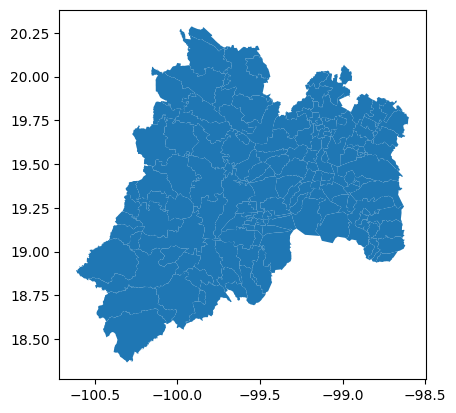

In [25]:
# Get unique state codes from properties dataframe
# entities = [s.zfill(2) for s in df_properties['state_id'].unique()]
entities = ['09', '15']
entities.sort()

# Get Mexico municipalities shapes
gdf_mexico_municipalities = inegi_api.Municipios(entidades=entities)
gdf_mexico_municipalities.shape
gdf_mexico_municipalities.plot()

In [26]:
# see municipalities
print(gdf_mexico_municipalities.shape)
gdf_mexico_municipalities.head()

(141, 10)


,geometry,cvegeo,cve_agee,cve_agem,nom_agem,cve_cab,pob,pob_fem,pob_mas,viv
0,"MULTIPOLYGON (((-99.12218 19.45975, -99.12210 ...",09017,09,017,Venustiano Carranza,----,443704,233586,210118,135789
1,"MULTIPOLYGON (((-99.19220 19.40372, -99.19219 ...",09010,09,010,Álvaro Obregón,----,759137,398130,361007,219445
2,"MULTIPOLYGON (((-99.14174 19.46582, -99.14165 ...",09015,09,015,Cuauhtémoc,----,545884,284933,260951,196593
3,"MULTIPOLYGON (((-99.12215 19.59248, -99.12078 ...",09005,09,005,Gustavo A. Madero,----,1173351,609477,563874,340301
4,"MULTIPOLYGON (((-99.25771 19.40474, -99.25772 ...",09004,09,004,Cuajimalpa de Morelos,----,217686,113537,104149,60442


## Model

In [14]:
# Get configuration
config_model, recaster_mappers, mlflow_config = get_configs(CONFIG_PATH)

# set mlflow
mlflow.set_tracking_uri(f"http://{mlflow_config['host']}:{mlflow_config['port']}")
mlflow.set_experiment(mlflow_config['experiment_name'])

# Load model from MLflow using only the model_id
model_path = f"runs:/{MODEL_ID}/models"
model = mlflow.xgboost.load_model(model_path)

# look
print(f"Model loaded from MLflow run ID: {MODEL_ID}")
model

Model loaded from MLflow run ID: 6c4b07101200430da8a657815014af7f


In [15]:
# load transformer
transformer_path = mlflow.artifacts.download_artifacts(
    run_id=MODEL_ID, 
    artifact_path="preprocessor/feature_transformer.joblib"
)
transformer = joblib.load(transformer_path)

# see transformer
transformer

In [16]:
# model features
model_feature_names = model.feature_names
model_feature_names

['half_bathrooms',
 'full_bathrooms',
 'age_in_months',
 'saleable_area',
 'land_area',
 'is_apartment',
 'parking_lots',
 'quarters_since_first_appraisal',
 'hex_embedding_1_d16_v2',
 'hex_embedding_2_d16_v2',
 'hex_embedding_3_d16_v2',
 'hex_embedding_4_d16_v2',
 'hex_embedding_5_d16_v2',
 'hex_embedding_6_d16_v2',
 'hex_embedding_7_d16_v2',
 'hex_embedding_8_d16_v2',
 'hex_embedding_9_d16_v2',
 'hex_embedding_10_d16_v2',
 'hex_embedding_11_d16_v2',
 'hex_embedding_12_d16_v2',
 'hex_embedding_13_d16_v2',
 'hex_embedding_14_d16_v2',
 'hex_embedding_15_d16_v2',
 'hex_embedding_16_d16_v2']

In [17]:
# validate transformer
print(f"y transformation: mean = {transformer.get_transformers()['target'].mean_}, var = {transformer.get_transformers()['target'].var_}")

y transformation: mean = [9.48384826], var = [0.1958993]


In [19]:
# validate transformer
pd.Series((
    get_target_value(df_properties['y_fitted'].values, transformer)
    - df_properties['y'].values
)).describe(

)

count    1908483.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
dtype: float64

---
# Index Construction (apartment)

## S1: Counterfactual

In [43]:
# target name
target_name = list(config_model['target'].keys())[0]
target_name_pred = f"{target_name}_pred"
print(f"Target name: {target_name}, prediction name: {target_name_pred}")

# see range of quarters since first appraisal
min_quarters = df_properties['quarters_since_first_appraisal'].min().astype(int)
max_quarters = df_properties['quarters_since_first_appraisal'].max().astype(int)
print(f"Range of quarters since first appraisal: {min_quarters} to {max_quarters}")

# get values
array_quarters = np.arange(min_quarters, max_quarters)
array_hex_id = gdf_hex_embeddings['hex_id'].unique()

# create dataframe with all combinations
df_cross = pd.MultiIndex.from_product(
    [array_hex_id, array_quarters],
    names=['hex_id', 'quarters_since_first_appraisal']
).to_frame(index=False)

# look
print(df_cross.shape)
df_cross.head()

Target name: ppsm_saleable, prediction name: ppsm_saleable_pred
Range of quarters since first appraisal: 0 to 20
(5234240, 2)


,hex_id,quarters_since_first_appraisal
0,89450984803ffff,0
1,89450984803ffff,1
2,89450984803ffff,2
3,89450984803ffff,3
4,89450984803ffff,4


In [44]:
# Create Counterfactual DataFrame
# merge with hex embeddings
df_cross = df_cross.merge(
    gdf_hex_embeddings,
    on='hex_id',
    how='left'
)

# canonical property
canonical_property = {
    # new property
    'age_in_months': 1,
    # characteristics
    'is_apartment': 1,
    'half_bathrooms': 0,
    'full_bathrooms': 1,
    'saleable_area': 60,
    'land_area': 60,
    'parking_lots': 1,
}

df_cross = df_cross.assign(**canonical_property)

# look
print(df_cross.shape)
df_cross.head()

(5234240, 25)


,hex_id,quarters_since_first_appraisal,hex_embedding_1_d16_v2,hex_embedding_2_d16_v2,hex_embedding_3_d16_v2,hex_embedding_4_d16_v2,hex_embedding_5_d16_v2,hex_embedding_6_d16_v2,hex_embedding_7_d16_v2,hex_embedding_8_d16_v2,hex_embedding_9_d16_v2,hex_embedding_10_d16_v2,hex_embedding_11_d16_v2,hex_embedding_12_d16_v2,hex_embedding_13_d16_v2,hex_embedding_14_d16_v2,hex_embedding_15_d16_v2,hex_embedding_16_d16_v2,age_in_months,is_apartment,half_bathrooms,full_bathrooms,saleable_area,land_area,parking_lots
0,89450984803ffff,0,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,1,1,0,1,60,60,1
1,89450984803ffff,1,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,1,1,0,1,60,60,1
2,89450984803ffff,2,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,1,1,0,1,60,60,1
3,89450984803ffff,3,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,1,1,0,1,60,60,1
4,89450984803ffff,4,1.226548,-2.105018,0.980468,0.004962,1.388463,-3.114058,0.175245,-0.141921,-1.121091,-1.674633,0.176828,0.982042,-2.988769,-0.198455,-2.142136,-1.020302,1,1,0,1,60,60,1


In [45]:
# describe non_hex features
non_hex_features = [col for col in df_cross.columns if not col.startswith('hex_')]
df_cross[non_hex_features].describe().T[['mean', 'std']].sort_values('std')

,mean,std
age_in_months,1.0,0.000000
is_apartment,1.0,0.000000
half_bathrooms,0.0,0.000000
full_bathrooms,1.0,0.000000
saleable_area,60.0,0.000000
land_area,60.0,0.000000
parking_lots,1.0,0.000000
quarters_since_first_appraisal,9.5,5.766282


## S2: Predict

In [46]:
# To DMatrix
dmat_counterfactual = xgb.DMatrix(df_cross[model_feature_names], enable_categorical=True)

# Subset features to only hex_id and quarters_since_first_appraisal
df_cross = df_cross[['hex_id', 'quarters_since_first_appraisal']]

# Predict
target_name = list(config_model['target'].keys())[0]
df_cross[target_name_pred] = get_predictions(model, dmat_counterfactual, transformer)

# look
print(df_cross.shape)
df_cross.head()

(5234240, 3)


,hex_id,quarters_since_first_appraisal,ppsm_saleable_pred
0,89450984803ffff,0,13109.525391
1,89450984803ffff,1,12397.688477
2,89450984803ffff,2,12915.441406
3,89450984803ffff,3,12630.882812
4,89450984803ffff,4,12211.930664


In [47]:
# transform quarters_since_first_appraisal to date
start_date = df_properties['valuation_date'].min()
df_cross = df_cross.assign(
    year=lambda x: start_date.year + x['quarters_since_first_appraisal'] // 4,
    quarter=lambda x: (x['quarters_since_first_appraisal'] % 4).astype(int) + 1,
    month=lambda x: x['quarter'] * 3,
    day=1,
    year_quarter=lambda x: pd.to_datetime(x[['year', 'month', 'day']]).dt.to_period('Q')
).drop(columns=['year', 'month', 'day', 'quarter', 'quarters_since_first_appraisal'])

# transform year_quarter to datetime
df_cross['year_quarter'] = df_cross['year_quarter'].dt.to_timestamp()

# sort values
df_cross = df_cross.sort_values(['hex_id', 'year_quarter'], ignore_index=True)

# look
print(df_cross.shape)
df_cross.head()

(5234240, 3)


,hex_id,ppsm_saleable_pred,year_quarter
0,8929a4c0003ffff,13857.660156,2019-01-01
1,8929a4c0003ffff,13953.074219,2019-04-01
2,8929a4c0003ffff,13771.353516,2019-07-01
3,8929a4c0003ffff,14744.637695,2019-10-01
4,8929a4c0003ffff,14234.774414,2020-01-01


In [48]:
# create index (base quarter is first quarter)
df_cross = (
    df_cross
    .assign(
        base_price=lambda x: x.groupby('hex_id')[target_name_pred].transform('first'),
        index=lambda x: x[target_name_pred] / x['base_price'] * 100
    )
)

# percentual change per hex_id
df_cross["index_pct_change"] = (
    df_cross
    .groupby('hex_id')['index']
    .pct_change()
)

# look
print(df_cross.shape)
df_cross.head()


(5234240, 6)


,hex_id,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
0,8929a4c0003ffff,13857.660156,2019-01-01,13857.660156,100.000000,NaN
1,8929a4c0003ffff,13953.074219,2019-04-01,13857.660156,100.688530,0.006885
2,8929a4c0003ffff,13771.353516,2019-07-01,13857.660156,99.377190,-0.013024
3,8929a4c0003ffff,14744.637695,2019-10-01,13857.660156,106.400635,0.070675
4,8929a4c0003ffff,14234.774414,2020-01-01,13857.660156,102.721344,-0.034580


---
# Index Analysis

## Zone-level explainability

In [ ]:
# hexagons to exemplify
dict_hex_example = {
    'roma': '894995ba39bffff',
    'polanco': '894995baebbffff',
    'santa_fe': '894995b3387ffff',
    'pedregal': '89499584ddbffff',
    'del_valle': '894995ba47bffff',
}

# to gdf
gdf_hexes_example = pd.DataFrame.from_dict(
    dict_hex_example,
    orient='index',
    columns=['hex_id']
    ).reset_index(

    ).rename(
        columns={'index': 'neighborhood'}
    ).set_index(
        'neighborhood'
    )

# get n krings for each hex
n_rings = 1
gdf_hexes_example = (
    gdf_hexes_example
    .loc[:, 'hex_id']
    .apply(lambda x: pd.Series(list(h3.k_ring(x, n_rings))))
    .stack()
    .to_frame('hex_id')
    .reset_index(1, drop=True)
    .reset_index()
)

# get geometry
gdf_hexes_example = (
    gdf_hexes_example
    .assign(
        geometry=lambda x: x['hex_id'].apply(lambda h: Polygon(h3.h3_to_geo_boundary(h, geo_json=True)))
    )
    .set_geometry('geometry')
    .set_crs(epsg=4326)
    .to_crs(epsg=6372)
)

# join with predictions
gdf_hexes_example = gdf_hexes_example.merge(
    df_cross,
    on='hex_id',
    how='inner'
)

# # look
print(gdf_hexes_example.shape)
gdf_hexes_example.head()

(700, 8)
(700, 8)


,neighborhood,hex_id,geometry,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
0,roma,894995ba393ffff,"POLYGON ((2796113.947 826519.807, 2796240.402 ...",62533.398438,2019-01-01,62533.398438,100.000000,NaN
1,roma,894995ba393ffff,"POLYGON ((2796113.947 826519.807, 2796240.402 ...",62853.988281,2019-04-01,62533.398438,100.512672,0.005127
2,roma,894995ba393ffff,"POLYGON ((2796113.947 826519.807, 2796240.402 ...",66242.218750,2019-07-01,62533.398438,105.930946,0.053906
3,roma,894995ba393ffff,"POLYGON ((2796113.947 826519.807, 2796240.402 ...",63885.820312,2019-10-01,62533.398438,102.162720,-0.035572
4,roma,894995ba393ffff,"POLYGON ((2796113.947 826519.807, 2796240.402 ...",68778.867188,2020-01-01,62533.398438,109.987411,0.076591


<Axes: >

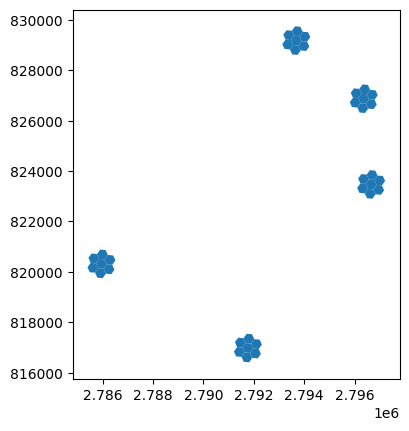

In [51]:
# plot
gdf_hexes_example[['neighborhood', 'geometry']].drop_duplicates().plot()

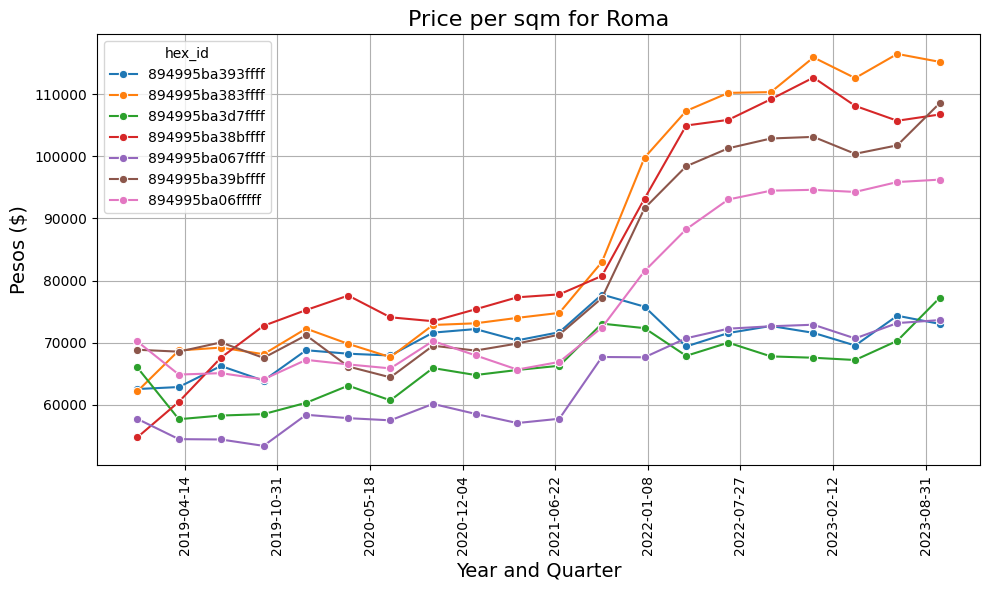

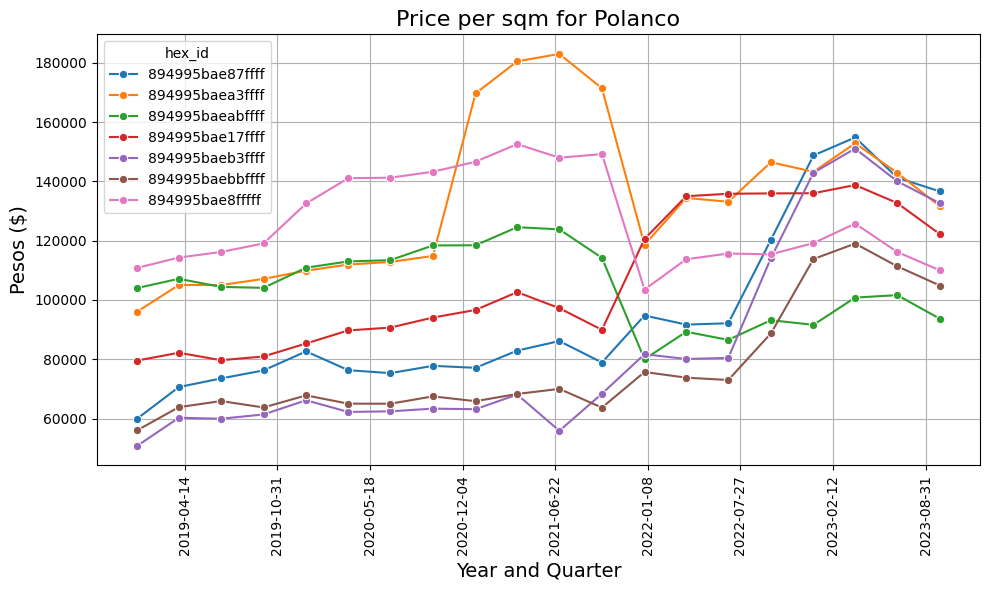

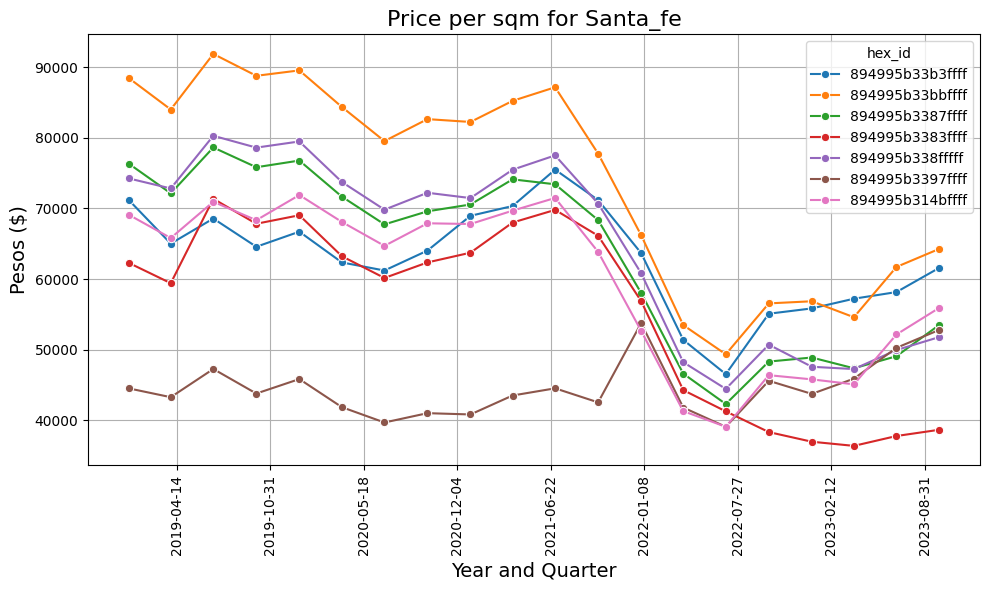

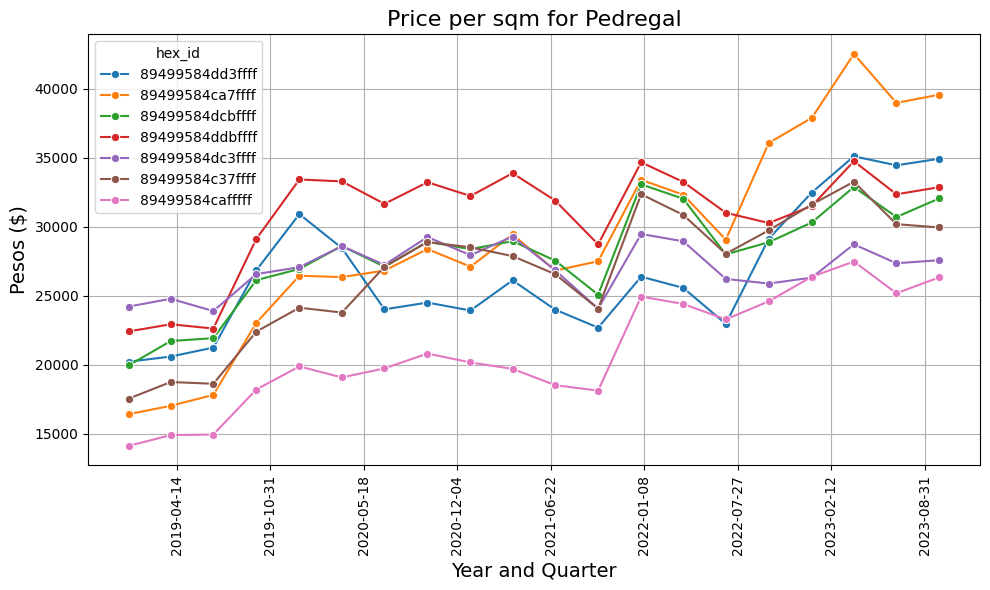

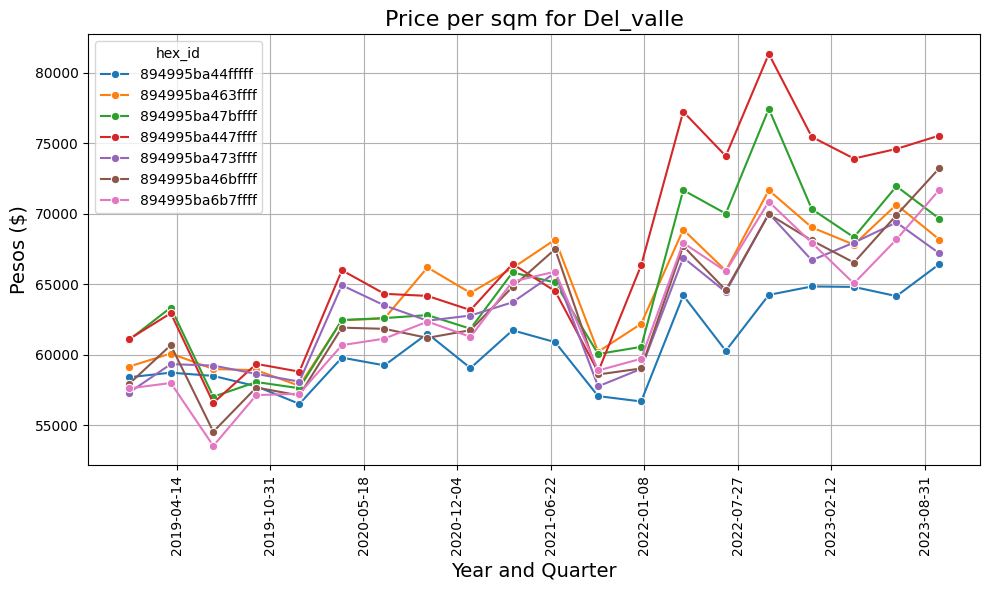

In [52]:
# for each neighborhood plot time series of housing index
for neighborhood in gdf_hexes_example['neighborhood'].unique():
    # subset
    gdf_plot = gdf_hexes_example.loc[lambda x:
        x['neighborhood'] == neighborhood
    ].copy()

    # plot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.lineplot(
        data=gdf_plot,
        x='year_quarter',
        y=target_name_pred,
        hue='hex_id',
        marker='o',
        ax=ax
    )
    ax.set_title(f"Price per sqm for {neighborhood.capitalize()}", fontsize=16)
    ax.set_xlabel("Year and Quarter", fontsize=14)
    ax.set_ylabel("Pesos ($)", fontsize=14)

    # x ticks for each year
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

    ax.grid(True)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


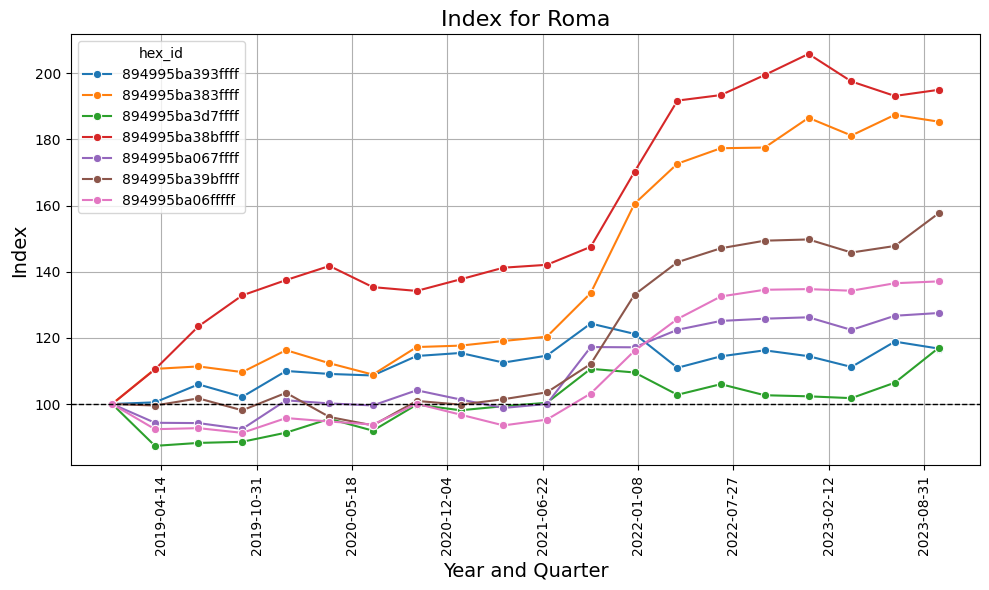

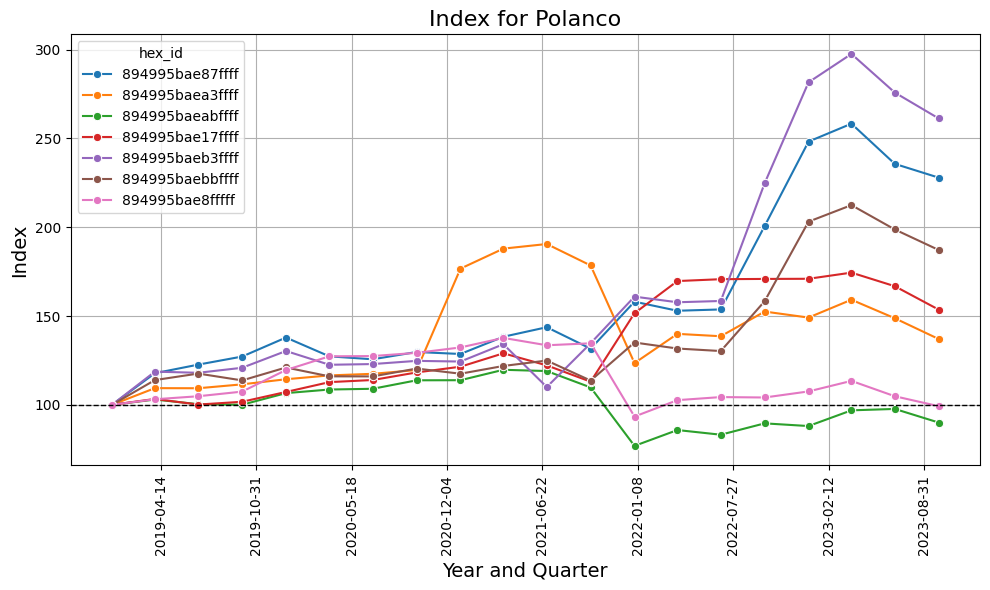

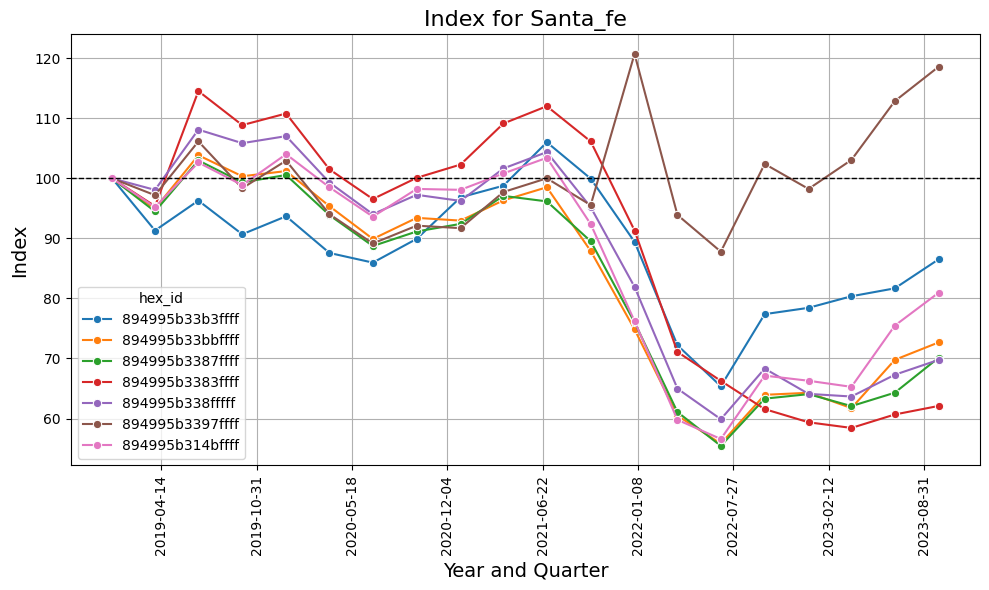

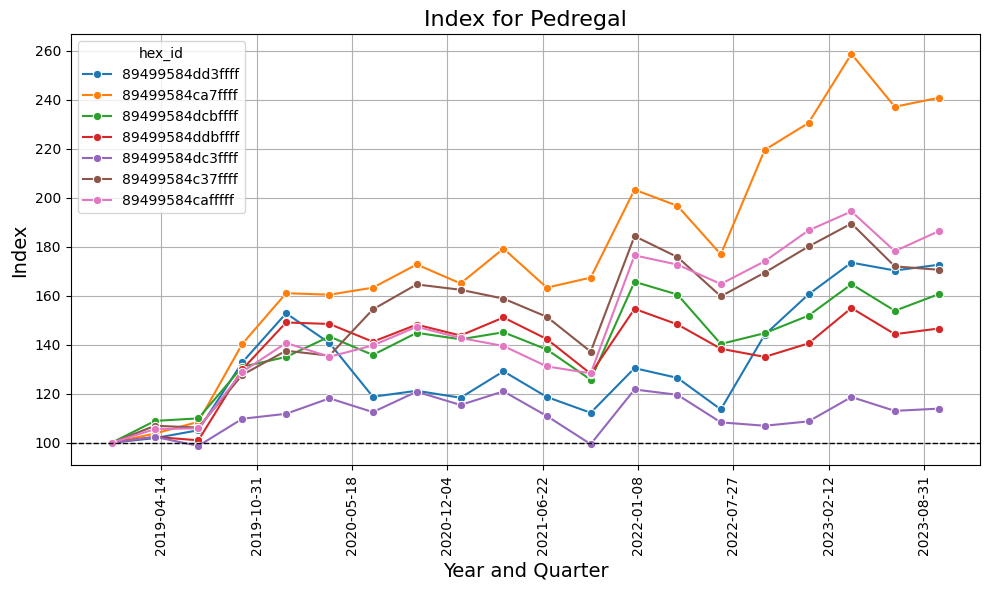

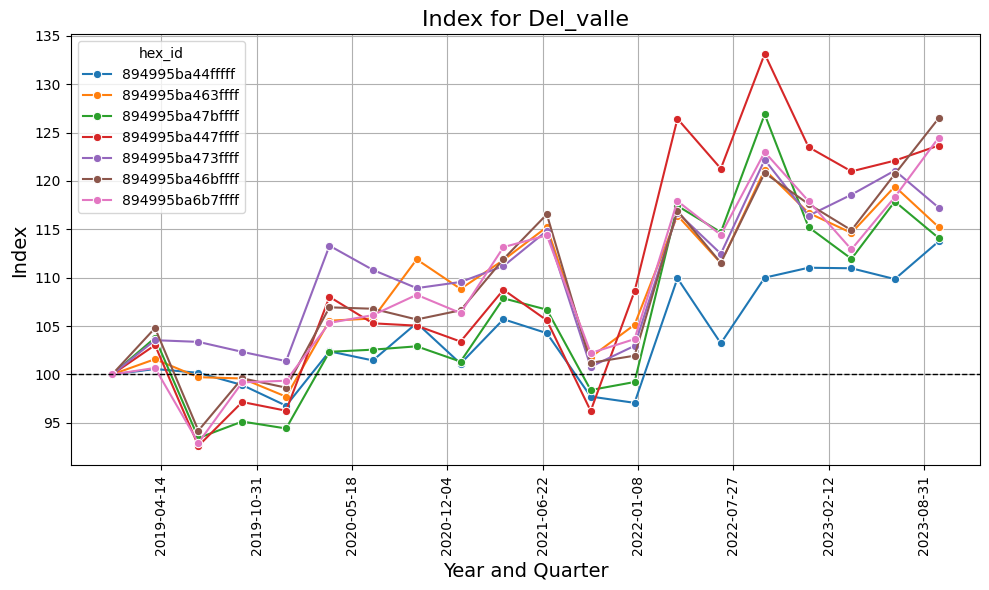

In [53]:
# for each neighborhood plot time series of housing index
for neighborhood in gdf_hexes_example['neighborhood'].unique():
    # subset
    gdf_plot = gdf_hexes_example.loc[lambda x:
        x['neighborhood'] == neighborhood
    ].copy()

    # plot
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.lineplot(
        data=gdf_plot,
        x='year_quarter',
        y='index',
        hue='hex_id',
        marker='o',
        ax=ax
    )
    ax.set_title(f"Index for {neighborhood.capitalize()}", fontsize=16)
    ax.set_xlabel("Year and Quarter", fontsize=14)
    ax.set_ylabel("Index", fontsize=14)

    # add horizontal line at y=100
    ax.axhline(100, color='k', linestyle='--', linewidth=1)

    # x ticks for each year
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

    ax.grid(True)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


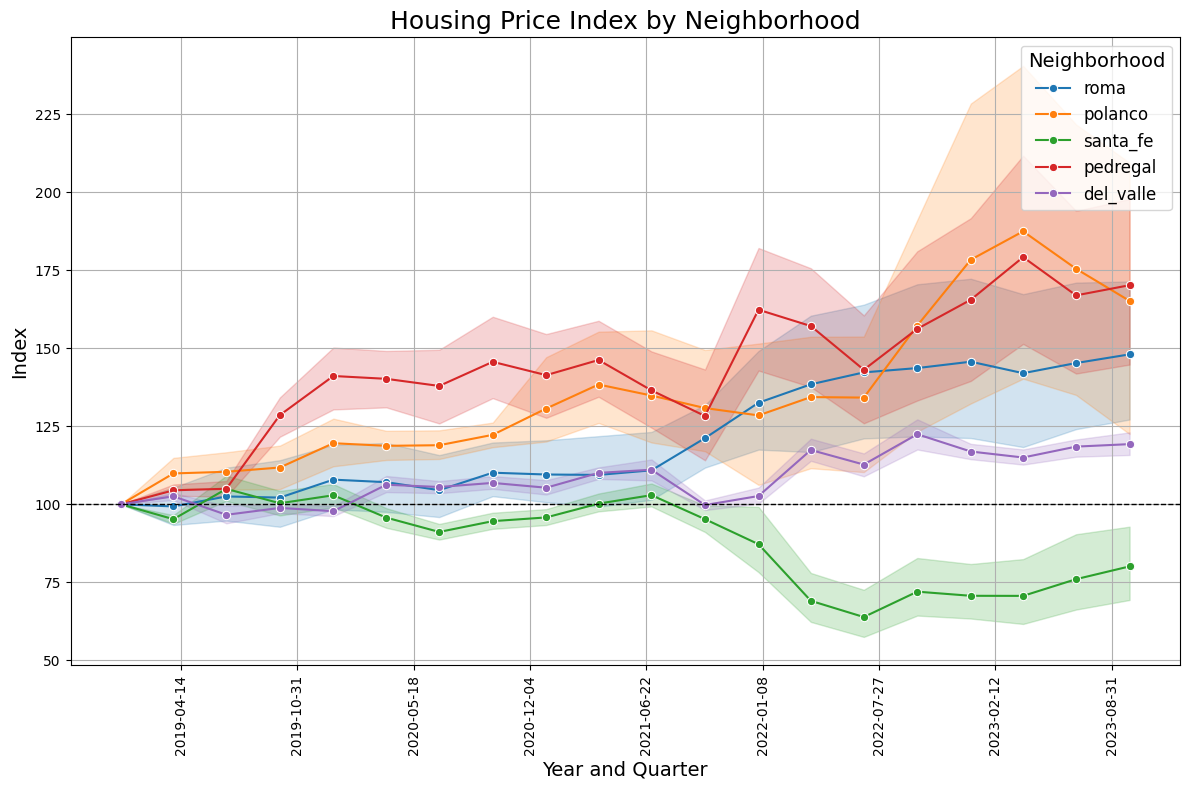

In [54]:
# plot all neighborhoods together
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_hexes_example,
    x='year_quarter',
    y='index',
    hue='neighborhood',
    marker='o',
    ax=ax,
    errorbar=('ci', 95)
)
ax.set_title("Housing Price Index by Neighborhood", fontsize=18)
ax.set_xlabel("Year and Quarter", fontsize=14)
ax.set_ylabel("Index", fontsize=14)

# add horizontal line at y=100
ax.axhline(100, color='k', linestyle='--', linewidth=1)

# x ticks for each year
ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

ax.grid(True)
plt.xticks(rotation=90)
plt.legend(title='Neighborhood', fontsize=12, title_fontsize=14)
plt.tight_layout()
plt.show()



<Axes: >

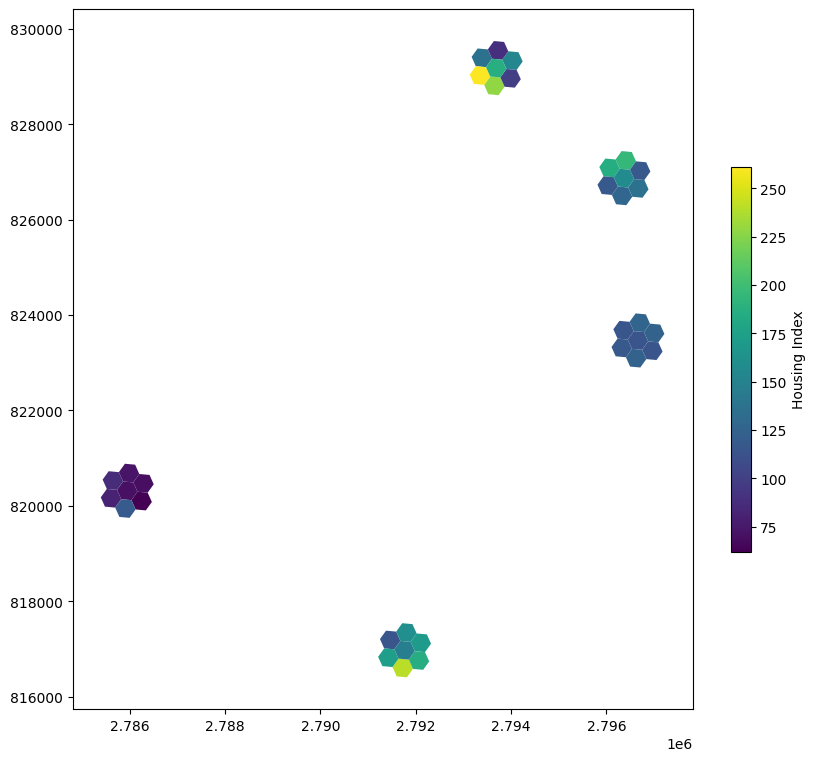

In [55]:
# get last quarter per hex_id and plot map
gdf_last_quarter = (
    gdf_hexes_example
    .sort_values(['hex_id', 'year_quarter'])
    .groupby('hex_id')
    .tail(1)
    .copy()
    .reset_index(drop=True)
)

# plot change in the map
fig, ax = plt.subplots(figsize=(10, 10))
gdf_last_quarter.plot(
    column='index',
    cmap='viridis',
    legend=True,
    legend_kwds={'label': "Housing Index", 'shrink': 0.5},
    ax=ax
)

## Municipality-level explainability

### Join municipalities with hexagons

In [56]:
# Get the polygon shape of each hex_id
gdf_hex_embeddings = (
    gdf_hex_embeddings
    .assign(
        geometry=lambda x: x['hex_id'].apply(lambda h: Polygon(h3.h3_to_geo_boundary(h, geo_json=True)))
    )
    .set_geometry('geometry')
    .set_crs(epsg=4326)
    .to_crs(epsg=6372)
)

In [57]:
# Spatial join to get municiaplity that intersects with hexagon
gdf_mexico_municipalities_hexes = (
    gdf_mexico_municipalities
    .loc[:, ['geometry', 'cvegeo', 'nom_agem']]
    .to_crs(epsg=6372)
    .sjoin(
        gdf_hex_embeddings[['hex_id', 'geometry']],
        how='inner',
        predicate='intersects'
    )
    .drop(columns=['index_right'])
)

# look
print(gdf_mexico_municipalities_hexes.shape)
gdf_mexico_municipalities_hexes.head()

(41696, 4)


,geometry,cvegeo,nom_agem,hex_id
0,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb563ffff
0,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb0a3ffff
0,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb56bffff
0,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb567ffff
0,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb0abffff


<Axes: >

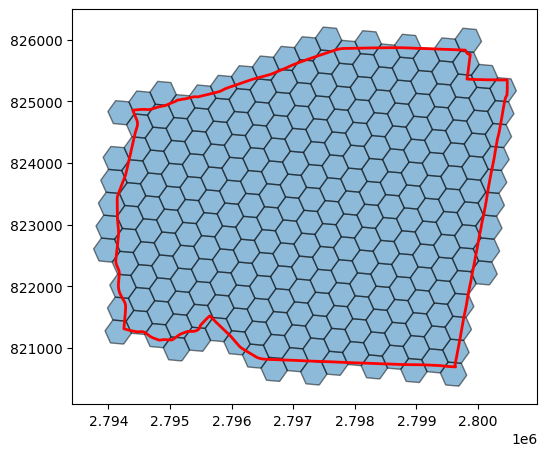

In [58]:
# Look for a specific cvegeo
# example cvegeo
example_cvegeo = '09014'  # Coyoacán, CDMX

# subset
gdf_example_hexes = gdf_mexico_municipalities_hexes.loc[lambda x: x['cvegeo'] == example_cvegeo]

# for each hex_id get its hex_geometry
gdf_example_hexes = gdf_example_hexes.merge(
    gdf_hex_embeddings[['hex_id', 'geometry']],
    on='hex_id',
    how='left'
).rename(columns={'geometry_x': 'municipality_geometry', 'geometry_y': 'hex_geometry'})

# set geometry to hex_geometry
gdf_example_hexes = gdf_example_hexes.set_geometry('hex_geometry')

# Plot
fig, ax = plt.subplots(figsize=(6, 6))

# plot first hexagons
gdf_example_hexes.plot(
    ax=ax,
    edgecolor='k',
    alpha=0.5
)

# plot municipality border
gdf_mexico_municipalities.to_crs(6372).loc[lambda x: x['cvegeo'] == example_cvegeo].plot(
    ax=ax,
    facecolor='none',
    edgecolor='r',
    linewidth=2
)


In [59]:
# Join with df_cross
gdf_cross = (
    gdf_mexico_municipalities_hexes
    .merge(
        df_cross,
        on='hex_id',
        how='inner'
    )
)

# look
print(gdf_cross.shape)
gdf_cross.head()

(833920, 9)


,geometry,cvegeo,nom_agem,hex_id,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
0,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb563ffff,30479.599609,2019-01-01,30479.599609,100.000000,NaN
1,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb563ffff,28872.701172,2019-04-01,30479.599609,94.727951,-0.052720
2,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb563ffff,30144.044922,2019-07-01,30479.599609,98.899086,0.044033
3,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb563ffff,29574.992188,2019-10-01,30479.599609,97.032089,-0.018878
4,"MULTIPOLYGON (((2801257.170 832076.851, 280126...",09017,Venustiano Carranza,894995bb563ffff,30331.195312,2020-01-01,30479.599609,99.513100,0.025569


### Aggregate by municipality and year_quarter

In [60]:
# bootstrap function
def boot_mean_ci_scipy(x, statistic=np.mean, alpha=0.05, n_resamples=200, random_state=42):
    # convert to numpy array
    a = np.asarray(x, dtype=float)

    # if len(a) < 2, return nans
    if len(a) < 2:
        return pd.Series({
            "qlow": np.nan,
            "qhigh": np.nan
        })

    # bootstrap
    res = bootstrap(
        (a,),
        statistic,
        confidence_level=1 - alpha,
        n_resamples=n_resamples,
        method="BCa",
        random_state=random_state
    )

    return pd.Series({
        "qlow": res.confidence_interval.low,
        "qhigh": res.confidence_interval.high
    })
    

In [61]:
# agg by municipality and year_quarter
gdf_cross_agg = (
    gdf_cross
    .groupby(['cvegeo', 'year_quarter'])
    .agg(
        n_hexes=('hex_id', 'nunique'),
        objective_value_pred_mean=(target_name_pred, 'mean'),
        # objective_value_pred_qlow=(target_name_pred, lambda x: boot_mean_ci_scipy(x)['qlow']),
        # objective_value_pred_qhigh=(target_name_pred, lambda x: boot_mean_ci_scipy(x)['qhigh']),
        objective_index_pred_std=(target_name_pred, 'std'),
    )
    .reset_index()
)

# append entity and municipality name
gdf_cross_agg = (
    gdf_cross_agg
    .assign(
        state_id=lambda x: x['cvegeo'].str.slice(0, 2),
        municipality_id=lambda x: x['cvegeo'].str.slice(2, 5)
    )
    .merge(
        gdf_mexico_states.loc[:, ['cvegeo', 'nom_agee', 'nom_abrev']],
        left_on='state_id',
        right_on='cvegeo',
        how='left'
    )
    .rename(columns={'cvegeo_x': 'cvegeo'})
    .drop(columns=['cvegeo_y'])
    .merge(
        gdf_mexico_municipalities.loc[:, ['cvegeo', 'nom_agem']],
        on='cvegeo',
        how='left'
    )
)

# look
print(gdf_cross_agg.shape)
gdf_cross_agg.head()

(1620, 10)


,cvegeo,year_quarter,n_hexes,objective_value_pred_mean,objective_index_pred_std,state_id,municipality_id,nom_agee,nom_abrev,nom_agem
0,09002,2019-01-01,317,27306.539062,5475.622112,09,002,Ciudad de México,CDMX,Azcapotzalco
1,09002,2019-04-01,317,27858.804688,6009.721183,09,002,Ciudad de México,CDMX,Azcapotzalco
2,09002,2019-07-01,317,29095.451172,6255.815994,09,002,Ciudad de México,CDMX,Azcapotzalco
3,09002,2019-10-01,317,28962.785156,6476.380837,09,002,Ciudad de México,CDMX,Azcapotzalco
4,09002,2020-01-01,317,29561.675781,6539.672310,09,002,Ciudad de México,CDMX,Azcapotzalco


In [62]:
# create index
gdf_cross_agg = (
    gdf_cross_agg
    .sort_values(['cvegeo', 'year_quarter'])
    .assign(
        base_price=lambda x: x.groupby('cvegeo')['objective_value_pred_mean'].transform('first'),
        index=lambda x: x['objective_value_pred_mean'] / x['base_price'] * 100,
        index_pct_change=lambda x: x.groupby('cvegeo')['index'].pct_change()
    )
)

# look
gdf_cross_agg.head()

,cvegeo,year_quarter,n_hexes,objective_value_pred_mean,objective_index_pred_std,state_id,municipality_id,nom_agee,nom_abrev,nom_agem,base_price,index,index_pct_change
0,09002,2019-01-01,317,27306.539062,5475.622112,09,002,Ciudad de México,CDMX,Azcapotzalco,27306.539062,100.000000,NaN
1,09002,2019-04-01,317,27858.804688,6009.721183,09,002,Ciudad de México,CDMX,Azcapotzalco,27306.539062,102.022469,0.020225
2,09002,2019-07-01,317,29095.451172,6255.815994,09,002,Ciudad de México,CDMX,Azcapotzalco,27306.539062,106.551216,0.044390
3,09002,2019-10-01,317,28962.785156,6476.380837,09,002,Ciudad de México,CDMX,Azcapotzalco,27306.539062,106.065384,-0.004560
4,09002,2020-01-01,317,29561.675781,6539.672310,09,002,Ciudad de México,CDMX,Azcapotzalco,27306.539062,108.258591,0.020678


### Time Series

##### Money based

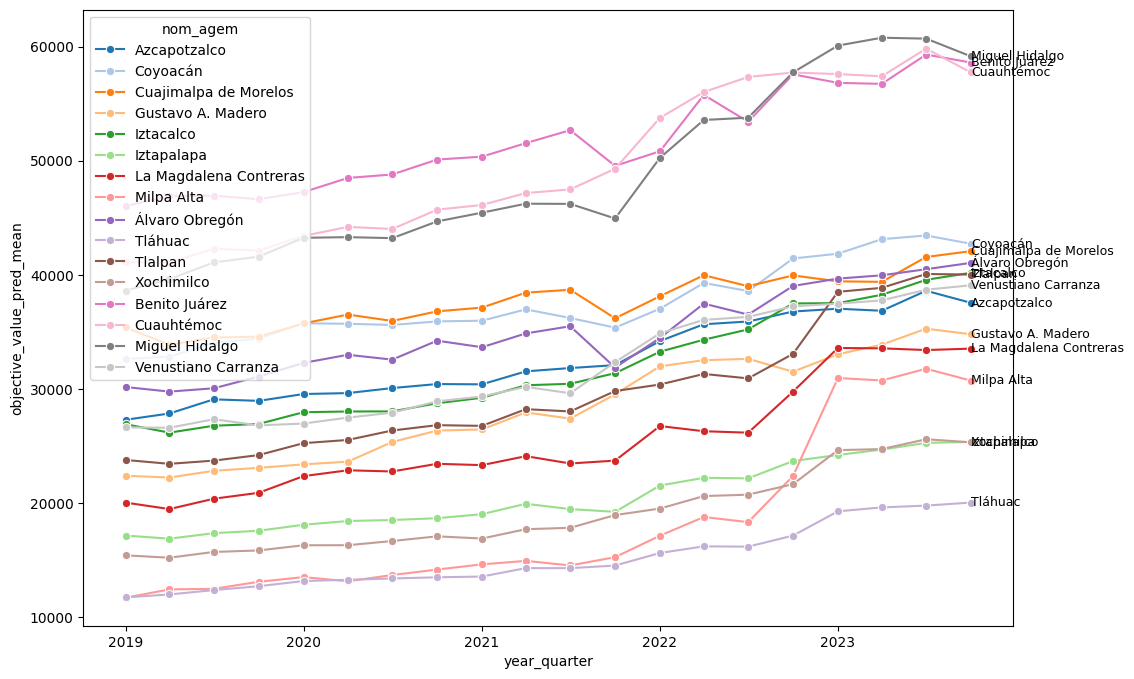

In [63]:
# for entity 09 (CDMX) plot all municipalities together
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_cross_agg.loc[lambda x: x['state_id'] == '09'],
    x='year_quarter',
    y='objective_value_pred_mean',
    hue='nom_agem',
    marker='o',
    ax=ax,
    palette='tab20',
)

# add the name of the municipality at the end of the lines
for municipality, group in gdf_cross_agg.loc[lambda x: x['state_id'] == '09'].groupby('nom_agem'):
    ax.text(
        group['year_quarter'].max(),
        group['objective_value_pred_mean'].values[-1],
        municipality,
        fontsize=9,
        verticalalignment='center'
    )

<Axes: xlabel='year_quarter', ylabel='ppsm_saleable_pred'>

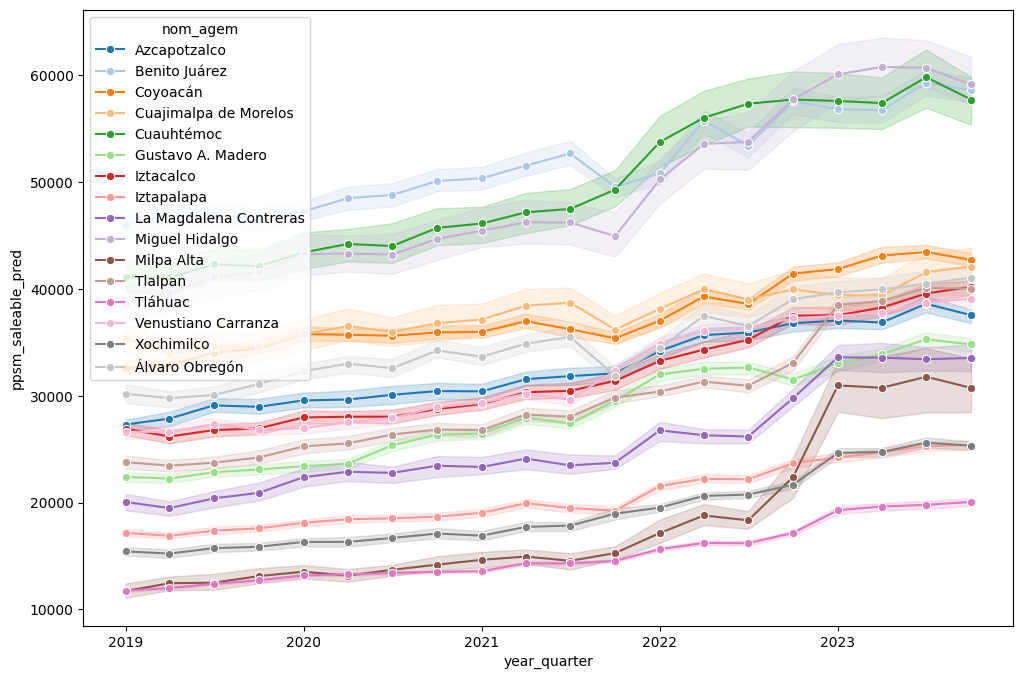

In [64]:
# for entity 09 (CDMX) plot all municipalities together
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_cross.loc[lambda x: x['cvegeo'].str.startswith('09')].sort_values(['nom_agem', 'year_quarter']),
    x='year_quarter',
    y='ppsm_saleable_pred',
    hue='nom_agem',
    marker='o',
    ax=ax,
    palette='tab20',
    errorbar=('ci', 95),
    n_boot=200
)

##### Index

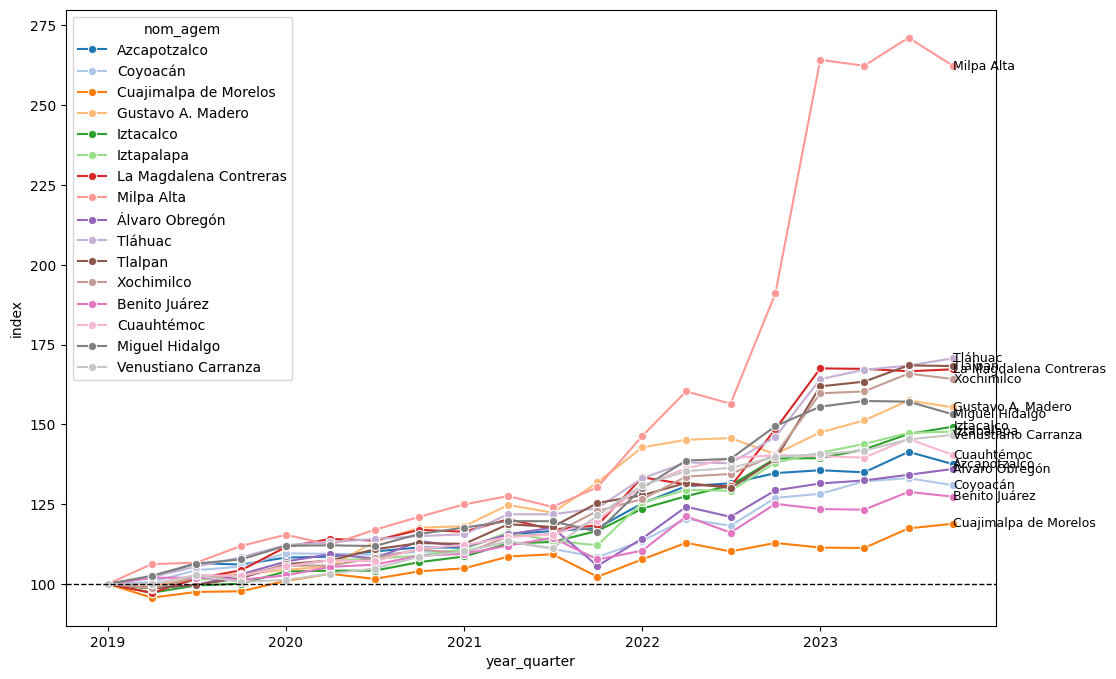

In [65]:
# for entity 09 (CDMX) plot all municipalities together
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_cross_agg.loc[lambda x: x['state_id'] == '09'],
    x='year_quarter',
    y='index',
    hue='nom_agem',
    marker='o',
    ax=ax,
    palette='tab20',
)

# add the name of the municipality at the end of the lines
for municipality, group in gdf_cross_agg.loc[lambda x: x['state_id'] == '09'].groupby('nom_agem'):
    ax.text(
        group['year_quarter'].max(),
        group['index'].values[-1],
        municipality,
        fontsize=9,
        verticalalignment='center'
    )

# add horizontal line at y=100
ax.axhline(100, color='k', linestyle='--', linewidth=1)

(wip): how can i bootstrap an index if x0 changes every time as also the mean?

## State-level explainability

### Join states with hexagons

In [70]:
# Spatial join to get states that intersects with hexagon
gdf_mexico_states_hexes = (
    gdf_mexico_states
    .loc[:, ['geometry', 'cvegeo', 'nom_agee', 'nom_abrev']]
    .to_crs(epsg=6372)
    .sjoin(
        gdf_hex_embeddings[['hex_id', 'geometry']],
        how='inner',
        predicate='intersects'
    )
    .drop(columns=['index_right'])
)

# look
print(gdf_mexico_states_hexes.shape)
gdf_mexico_states_hexes.head()

(258203, 5)


,geometry,cvegeo,nom_agee,nom_abrev,hex_id
0,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac563ffff
0,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac0a3ffff
0,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac56bffff
0,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac0abffff
0,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac0a7ffff


Text(0.5, 1.0, 'State: México')

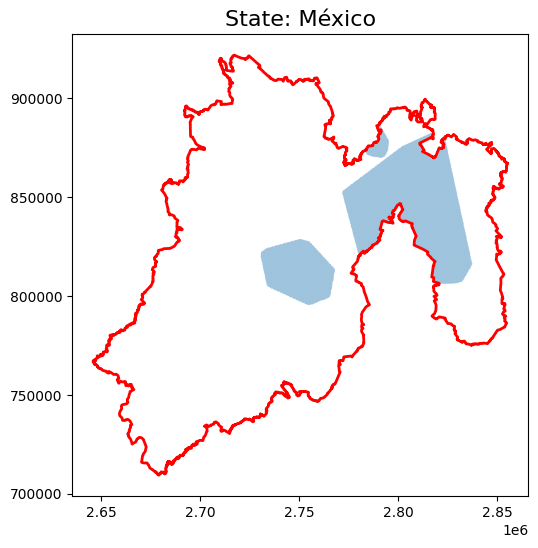

In [71]:
# Look for all hexes in a specific state
# example cvegeo
example_cvegeo = '15'

# subset
gdf_example_hexes = gdf_mexico_states_hexes.loc[lambda x: x['cvegeo'] == example_cvegeo]

# for each hex_id get its hex_geometry
gdf_example_hexes = gdf_example_hexes.merge(
    gdf_hex_embeddings[['hex_id', 'geometry']],
    on='hex_id',
    how='left'
).rename(columns={'geometry_x': 'municipality_geometry', 'geometry_y': 'hex_geometry'})

# set geometry to hex_geometry
gdf_example_hexes = gdf_example_hexes.set_geometry('hex_geometry')

# Plot
fig, ax = plt.subplots(figsize=(6, 6))

# plot first hexagons
gdf_example_hexes.plot(
    ax=ax,
    alpha=0.5
)

# plot state border
gdf_mexico_states.to_crs(6372).loc[lambda x: x['cvegeo'] == example_cvegeo].plot(
    ax=ax,
    facecolor='none',
    edgecolor='r',
    linewidth=2
)

# add name of the state
state_name = gdf_mexico_states.loc[lambda x: x['cvegeo'] == example_cvegeo, 'nom_agee'].values[0]
plt.title(f"State: {state_name}", fontsize=16)


In [72]:
# join with df_cross
gdf_cross = (
    gdf_mexico_states_hexes
    .merge(
        df_cross,
        on='hex_id',
        how='inner'
    )
)

# look
print(gdf_cross.shape)
gdf_cross.head()

(5164060, 10)


,geometry,cvegeo,nom_agee,nom_abrev,hex_id,ppsm_saleable_pred,year_quarter,base_price,index,index_pct_change
0,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac563ffff,8974.267578,2019-01-01,8974.267578,100.000000,NaN
1,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac563ffff,9051.314453,2019-04-01,8974.267578,100.858536,0.008585
2,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac563ffff,8941.803711,2019-07-01,8974.267578,99.638252,-0.012099
3,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac563ffff,9077.205078,2019-10-01,8974.267578,101.147034,0.015143
4,"MULTIPOLYGON (((2469550.852 1159302.643, 24697...",01,Aguascalientes,Ags.,89498eac563ffff,9696.808594,2020-01-01,8974.267578,108.051254,0.068259


### Aggregate by state and year_quarter

In [73]:
# agg by municipality and year_quarter
gdf_cross_agg = (
    gdf_cross
    .groupby(['cvegeo', 'year_quarter'])
    .agg(
        n_hexes=('hex_id', 'nunique'),
        objective_value_pred_mean=(target_name_pred, 'mean'),
        # objective_value_pred_qlow=(target_name_pred, lambda x: boot_mean_ci_scipy(x)['qlow']),
        # objective_value_pred_qhigh=(target_name_pred, lambda x: boot_mean_ci_scipy(x)['qhigh']),
        objective_index_pred_std=(target_name_pred, 'std'),
    )
    .reset_index()
)

# append entity and municipality name
gdf_cross_agg = (
    gdf_cross_agg
    .assign(
        state_id=lambda x: x['cvegeo'].str.slice(0, 2),
    )
    .merge(
        gdf_mexico_states.loc[:, ['cvegeo', 'nom_agee', 'nom_abrev']],
        left_on='state_id',
        right_on='cvegeo',
        how='left'
    )
    .rename(columns={'cvegeo_x': 'cvegeo'})
    .drop(columns=['cvegeo_y'])
)

# create index
gdf_cross_agg = (
    gdf_cross_agg
    .sort_values(['cvegeo', 'year_quarter'])
    .assign(
        base_price=lambda x: x.groupby('cvegeo')['objective_value_pred_mean'].transform('first'),
        index=lambda x: x['objective_value_pred_mean'] / x['base_price'] * 100,
        index_pct_change=lambda x: x.groupby('cvegeo')['index'].pct_change()
    )
)

# look
print(gdf_cross_agg.shape)
gdf_cross_agg.head()

(640, 11)


,cvegeo,year_quarter,n_hexes,objective_value_pred_mean,objective_index_pred_std,state_id,nom_agee,nom_abrev,base_price,index,index_pct_change
0,01,2019-01-01,3772,9423.015625,2785.297008,01,Aguascalientes,Ags.,9423.015625,100.000000,NaN
1,01,2019-04-01,3772,9565.159180,2800.135340,01,Aguascalientes,Ags.,9423.015625,101.508476,0.015085
2,01,2019-07-01,3772,9799.264648,2798.103628,01,Aguascalientes,Ags.,9423.015625,103.992867,0.024475
3,01,2019-10-01,3772,9970.576172,2823.151603,01,Aguascalientes,Ags.,9423.015625,105.810883,0.017482
4,01,2020-01-01,3772,10255.350586,3051.777063,01,Aguascalientes,Ags.,9423.015625,108.833000,0.028561


### Time Series

#### Money based

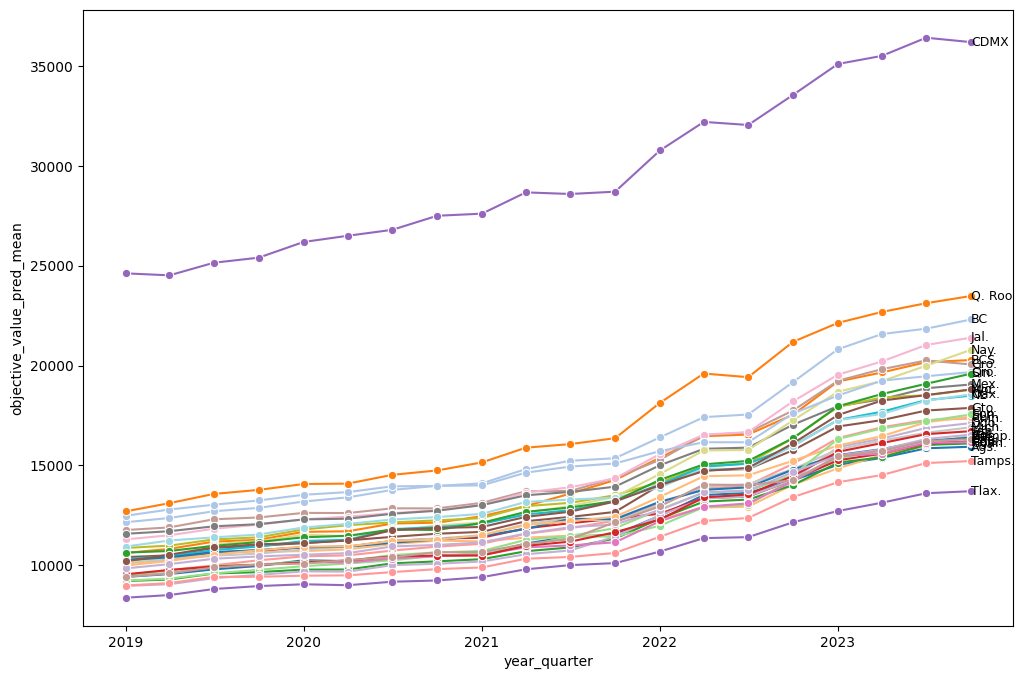

In [74]:
# for all the country
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_cross_agg,
    x='year_quarter',
    y='objective_value_pred_mean',
    hue='nom_abrev',
    marker='o',
    ax=ax,
    palette='tab20',
    legend=False
)

# add the name of the state at the end of the lines
for state, group in gdf_cross_agg.groupby('nom_abrev'):
    ax.text(
        group['year_quarter'].max(),
        group['objective_value_pred_mean'].values[-1],
        state,
        fontsize=9,
        verticalalignment='center'
    )

<Axes: xlabel='year_quarter', ylabel='ppsm_saleable_pred'>

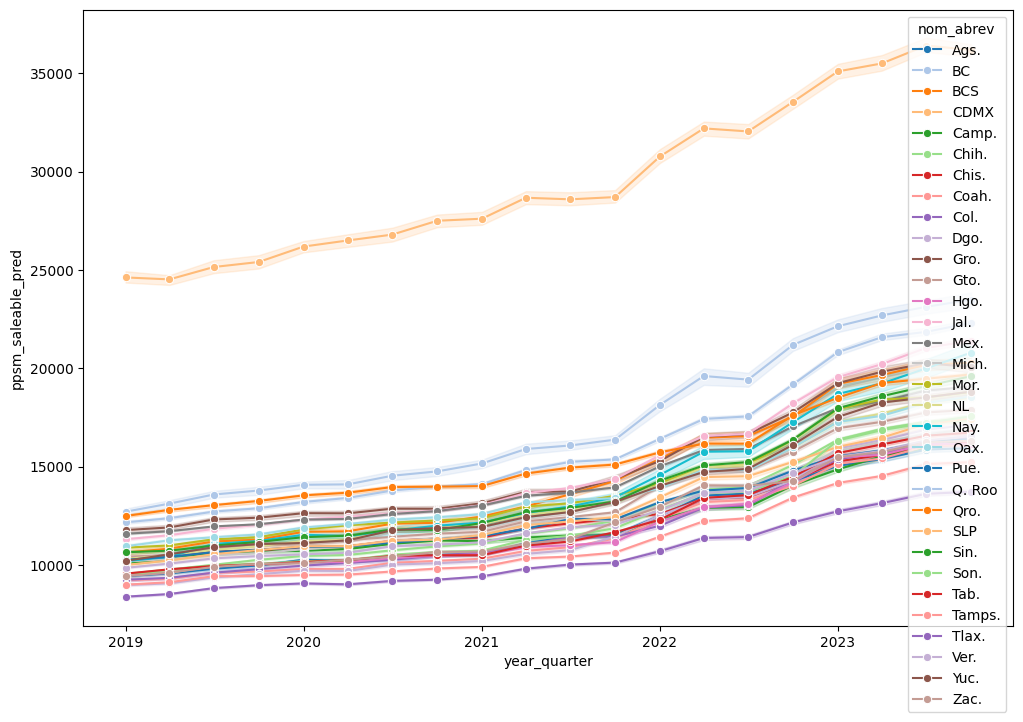

In [75]:
# for entity 09 (CDMX) plot all municipalities together
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_cross.sort_values(['nom_abrev', 'year_quarter']),
    x='year_quarter',
    y='ppsm_saleable_pred',
    hue='nom_abrev',
    marker='o',
    ax=ax,
    palette='tab20',
    errorbar=('ci', 95),
    n_boot=200
)

#### Index

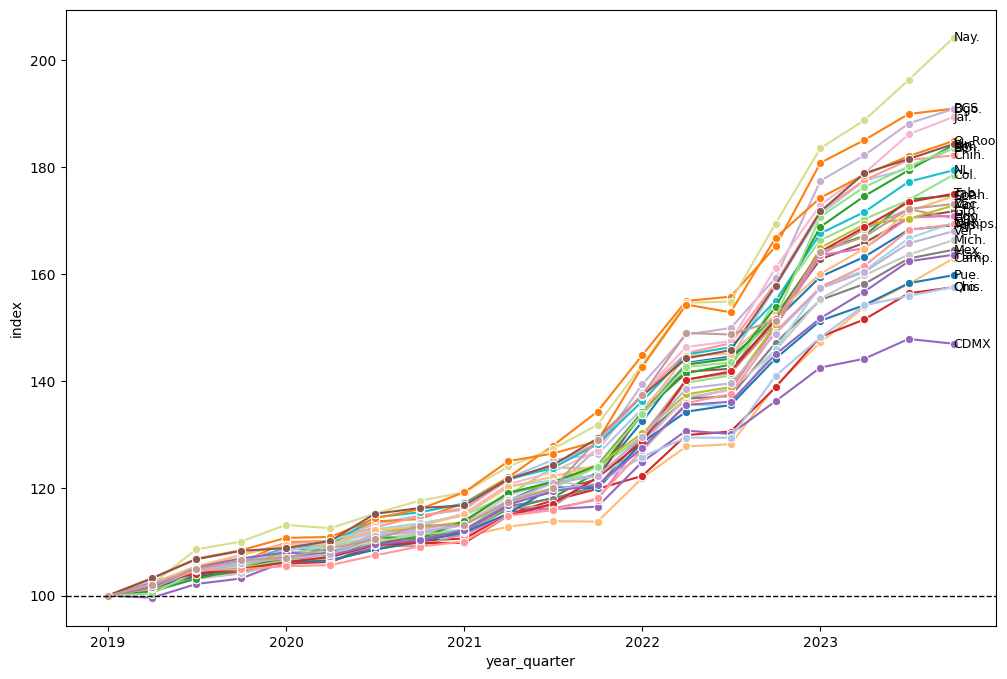

In [76]:
# for all the country
fig, ax = plt.subplots(figsize=(12, 8))
sns.lineplot(
    data=gdf_cross_agg,
    x='year_quarter',
    y='index',
    hue='nom_abrev',
    marker='o',
    ax=ax,
    palette='tab20',
    legend=False
)

# add the name of the municipality at the end of the lines
for municipality, group in gdf_cross_agg.groupby('nom_abrev'):
    ax.text(
        group['year_quarter'].max(),
        group['index'].values[-1],
        municipality,
        fontsize=9,
        verticalalignment='center'
    )

# add horizontal line at y=100
ax.axhline(100, color='k', linestyle='--', linewidth=1)

---
# SHF Comparisson